# Journée Data Science n°2 — Exploration et visualisation des collemboles

**Sujet.** On cherche à comprendre ce qui favorise la diversité des collemboles dans les sols, à partir d'échantillons géolocalisés et des caractéristiques physico-chimiques de leur site. La suite du travail (bloc modélisation) utilisera un modèle de régression pour identifier les variables importantes.

**Données.**

| Fichier | Contenu | Dimensions |
|---|---|---|
| `data_merged.csv` | jointure comptages + sol, une ligne par échantillon | 418 × 46 |
| `collembola_data_year1_train.csv` | comptages par espèce (matrice d'abondance) | 418 × 107 |
| `BISES_data_sites.csv` | caractéristiques du sol, une ligne par site | 174 × 31 |

**Périmètre de ce notebook :** exploration, contrôle qualité, visualisation. Il prépare le terrain pour la régression mais n'ajuste pas de modèle.

## Plan

1. Chargement et dictionnaire des variables
2. Qualité des données (doublons, manquants, cohérence, structure du plan)
3. Nettoyage et construction des jeux de travail
4. Exploration univariée
5. Exploration bivariée (indices × facteurs, indices × sol)
6. Structures multivariées (corrélations, ACP)
7. Ce qu'il faut corriger avant de modéliser
8. Les espèces (fichier brut)
9. Synthèse et suite

## Trois précautions de lecture

- **Pseudo-réplication.** 418 échantillons pour 140 sites : le sol est mesuré une fois par site puis répété sur ses ~3 réplicats. Les échantillons d'un même site ne sont pas indépendants ; une corrélation calculée sur 418 lignes surestime la précision. Le nombre de profils de sol indépendants est le nombre de sites.
- **Beaucoup de zéros.** 28 échantillons n'ont aucun collembole ; l'abondance `A` est très asymétrique (0 à 593) et appelle une échelle log.
- **`J` indéfini n'est pas une erreur de saisie.** `J = H / log(S)` n'a pas de sens quand `S = 0` ou `S = 1` (division par 0 ou par `log(1) = 0`). Ces valeurs restent manquantes, elles ne sont pas imputées.

## 0. Imports et configuration

Tout est relatif au dossier du notebook : il suffit de l'ouvrir depuis le dossier `data science 2`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "figure.autolayout": True,
})

DATA = Path.cwd()
print("Dossier de travail :", DATA)

Dossier de travail : C:\Documents\M1 MIASHS\modèles de régression linéaire et outils du diagnostic\data science 2


In [2]:
def lire_csv(nom):
    """Charge un CSV du dossier : séparateur ';', virgule décimale, BOM éventuel."""
    return pd.read_csv(DATA / nom, sep=";", decimal=",", encoding="utf-8-sig")


df    = lire_csv("data_merged.csv")            # jeu de travail principal
brut  = lire_csv("collembola_data_year1_train.csv")  # comptages par espèce
sites = lire_csv("BISES_data_sites.csv")       # sol par site (source de la jointure)

print(f"data_merged : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"brut        : {brut.shape[0]} lignes x {brut.shape[1]} colonnes")
print(f"sites       : {sites.shape[0]} lignes x {sites.shape[1]} colonnes")
df.head()

data_merged : 418 lignes x 46 colonnes
brut        : 418 lignes x 107 colonnes
sites       : 174 lignes x 31 colonnes


,Echantillon,Site,site_base,variante,replicat,city,land_use,site_group,sol_impute,A,S,H,J,Acari_Gamasides,Acari_Oribates,Acari_others,Acari_total,Other_microarthropodes,total_microarthropodes,Argile,Limon,Sable,Conduct,pH.eau,Carbonates,Calcaire,C..orga,Mat_org,Azote,C.N,P2O5,CEC,K2O,MgO,CaO,Na2O,Al,Cd,Co,Cr,Cu,Fe,Mn,Ni,Pb,Zn
0,BISES_MO_FU_CDN_1,BISES_MO_FU_CDN,BISES_MO_FU_CDN,aucune,1,MO,FU,Food Production,non,54,8,1.270441,0.610953,9,2,7,18,2,74,234,221,546.0,0.23,7.9,6,0.0,37.1,64.2,2.85,13.0,0.14,221.0,0.320,0.35,4.00,0.024,35.1,0.19,5.5,39.8,144.0,14.7,0.21,17.3,81.4,49.7
1,BISES_MO_FU_CDN_2,BISES_MO_FU_CDN,BISES_MO_FU_CDN,aucune,2,MO,FU,Food Production,non,38,5,1.000973,0.621939,69,8,78,155,6,199,234,221,546.0,0.23,7.9,6,0.0,37.1,64.2,2.85,13.0,0.14,221.0,0.320,0.35,4.00,0.024,35.1,0.19,5.5,39.8,144.0,14.7,0.21,17.3,81.4,49.7
2,BISES_MO_FU_CDN_3,BISES_MO_FU_CDN,BISES_MO_FU_CDN,aucune,3,MO,FU,Food Production,non,0,0,0.000000,NaN,80,3,9,92,7,99,234,221,546.0,0.23,7.9,6,0.0,37.1,64.2,2.85,13.0,0.14,221.0,0.320,0.35,4.00,0.024,35.1,0.19,5.5,39.8,144.0,14.7,0.21,17.3,81.4,49.7
3,BISES_MO_FU_ECT_1,BISES_MO_FU_ECT,BISES_MO_FU_ECT,aucune,1,MO,FU,Food Production,non,11,5,1.366711,0.849185,15,30,4,49,73,133,222,259,519.0,0.16,7.8,126,31.0,55.2,95.4,4.84,11.4,0.19,311.0,0.058,0.14,2.67,0.027,33.5,0.34,5.9,42.7,159.0,15.3,0.34,20.8,51.2,90.9
4,BISES_MO_FU_ECT_2,BISES_MO_FU_ECT,BISES_MO_FU_ECT,aucune,2,MO,FU,Food Production,non,8,3,1.039721,0.946395,22,20,0,42,3,53,222,259,519.0,0.16,7.8,126,31.0,55.2,95.4,4.84,11.4,0.19,311.0,0.058,0.14,2.67,0.027,33.5,0.34,5.9,42.7,159.0,15.3,0.34,20.8,51.2,90.9


## 1. Dictionnaire des variables

Les 46 colonnes se lisent en cinq blocs. Les unités des variables de sol ne sont pas documentées dans le dossier : on ne les suppose pas.

In [3]:
ID = ["Echantillon", "Site", "site_base", "variante", "replicat",
      "city", "land_use", "site_group", "sol_impute"]

INDICES = ["A", "S", "H", "J"]

MICRO = ["Acari_Gamasides", "Acari_Oribates", "Acari_others", "Acari_total",
         "Other_microarthropodes", "total_microarthropodes"]

PHYSIQUE = ["Argile", "Limon", "Sable", "Conduct"]
CHIMIE   = ["pH.eau", "Carbonates", "Calcaire", "C..orga", "Mat_org", "Azote",
            "C.N", "P2O5", "CEC", "K2O", "MgO", "CaO", "Na2O", "Al"]
METAUX   = ["Cd", "Co", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "Zn"]
SOL      = PHYSIQUE + CHIMIE + METAUX

assert len(SOL) == 27 and set(SOL) | set(ID) | set(INDICES) | set(MICRO) == set(df.columns), \
    "La liste des variables ne couvre pas exactement les colonnes du fichier."

descriptions = {
    "Echantillon": "identifiant unique de l'échantillon (Site + variante + réplicat)",
    "Site": "identifiant du site (en général 3 réplicats par site)",
    "site_base": "site sans le suffixe de variante ; 3 bases portent deux variantes P/RU",
    "variante": "aucune / P / RU — les variantes P et RU n'existent qu'à NY, usage PU",
    "replicat": "numéro du réplicat (1 à 3)",
    "city": "code ville (MO, NS, NY, PA)",
    "land_use": "usage du sol (FU, JP, LV, PU, RP)",
    "site_group": "regroupement d'usage : Food Production, Leisure, Traffic",
    "sol_impute": "non, ou nom de la règle d'imputation du sol pour 2 sites",
    "A": "abondance : nombre total d'individus (collemboles)",
    "S": "richesse : nombre de taxons avec au moins un individu",
    "H": "indice de diversité de Shannon",
    "J": "équitabilité de Pielou = H / log(S), indéfinie si S <= 1",
    "Argile": "fraction argile (texture)",
    "Limon": "fraction limon (texture)",
    "Sable": "fraction sable (texture) ; Argile + Limon + Sable ~ 1000",
    "Conduct": "conductivité",
    "pH.eau": "pH mesuré dans l'eau",
    "Carbonates": "carbonates totaux",
    "Calcaire": "calcaire",
    "C..orga": "carbone organique",
    "Mat_org": "matière organique ; Mat_org ~ 1,73 x C..orga (facteur de Van Bemmelen)",
    "Azote": "azote total",
    "C.N": "rapport C/N, cohérent avec C..orga / Azote",
    "P2O5": "phosphore assimilable",
    "CEC": "capacité d'échange cationique",
    "K2O": "potassium échangeable",
    "MgO": "magnésium échangeable",
    "CaO": "calcium échangeable",
    "Na2O": "sodium échangeable",
    "Al": "aluminium",
}

dico = pd.DataFrame(
    [{"groupe": groupe, "variable": v, "description": descriptions.get(v, "élément / métal trace")}
     for groupe, cols in [
         ("Identifiants / plan", ID),
         ("Indices de diversité", INDICES),
         ("Mésofaune (comptages)", MICRO),
         ("Sol — physique", PHYSIQUE),
         ("Sol — chimie", CHIMIE),
         ("Sol — éléments / métaux", METAUX),
     ]
     for v in cols]
)
dico

,groupe,variable,description
0,Identifiants / plan,Echantillon,identifiant unique de l'échantillon (Site + va...
1,Identifiants / plan,Site,identifiant du site (en général 3 réplicats pa...
2,Identifiants / plan,site_base,site sans le suffixe de variante ; 3 bases por...
3,Identifiants / plan,variante,aucune / P / RU — les variantes P et RU n'exis...
4,Identifiants / plan,replicat,numéro du réplicat (1 à 3)
5,Identifiants / plan,city,"code ville (MO, NS, NY, PA)"
6,Identifiants / plan,land_use,"usage du sol (FU, JP, LV, PU, RP)"
7,Identifiants / plan,site_group,"regroupement d'usage : Food Production, Leisur..."
8,Identifiants / plan,sol_impute,"non, ou nom de la règle d'imputation du sol po..."
9,Indices de diversité,A,abondance : nombre total d'individus (collembo...


## 2. Qualité des données

Objectif : vérifier que le fichier joint est sain avant de l'interpréter. On regarde les doublons, les manquants, la cohérence des indices recalculés depuis la matrice d'espèces, puis la structure du plan d'échantillonnage.

In [4]:
bilan = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs uniques": df.nunique(),
    "manquants": df.isna().sum(),
})

print("Doublons d'identifiant Echantillon :", df.Echantillon.duplicated().sum())
print("Lignes entièrement dupliquées       :", df.duplicated().sum())
print("Colonnes avec au moins un manquant  :", bilan.index[bilan.manquants > 0].tolist())
bilan.loc[bilan.manquants > 0]

Doublons d'identifiant Echantillon : 0


Lignes entièrement dupliquées       : 0
Colonnes avec au moins un manquant  : ['J']


,type,valeurs uniques,manquants
J,float64,202,81


### 2.1 Les 81 `J` manquants sont structurels

`J = H / log(S)` : si `S = 0` (aucun individu) la division est indéfinie, si `S = 1` le dénominateur vaut `log(1) = 0`.

In [5]:
table_manquants = pd.crosstab(df.S, df.J.isna()).rename(columns={False: "J défini", True: "J manquant"})
print("Répartition des échantillons selon S et la présence de J :")
table_manquants.loc[table_manquants.index <= 3].loc[:, ["J défini", "J manquant"]]

Répartition des échantillons selon S et la présence de J :


J,J défini,J manquant
S,,
0,0,28
1,0,53
2,78,0
3,79,0


### 2.2 Les indices fournis sont-ils cohérents avec la matrice d'espèces ?

On recalcule `A`, `S` et `H` depuis `collembola_data_year1_train.csv` (formule de Shannon en base naturelle, comme `vegan::diversity`) et on compare aux colonnes fournies. `J` n'est pas recalculé : il se déduit de `H` et `S`.

In [6]:
colonnes_exclues = ["Unnamed: 0", "Echantillon", "total_collembola",
                    "Acari_Gamasides", "Acari_Oribates", "Acari_others", "Acari_total",
                    "Other_microarthropodes", "total_microarthropodes"]
especes = brut.drop(columns=[c for c in colonnes_exclues if c in brut.columns])

A_rec = especes.sum(axis=1)
S_rec = (especes > 0).sum(axis=1)
P_rec = especes.div(A_rec.replace(0, np.nan), axis=0).values
with np.errstate(divide="ignore", invalid="ignore"):
    contributions = np.where(P_rec > 0, P_rec * np.log(P_rec), 0.0)
H_rec = pd.Series(-np.nansum(contributions, axis=1), index=especes.index)

verif = (pd.DataFrame({"Echantillon": brut["Echantillon"], "A_rec": A_rec, "S_rec": S_rec, "H_rec": H_rec})
         .merge(df[["Echantillon", "A", "S", "H"]], on="Echantillon", validate="one_to_one"))

ecarts = pd.Series({
    "A": (verif.A_rec - verif.A).abs().max(),
    "S": (verif.S_rec - verif.S).abs().max(),
    "H": (verif.H_rec - verif.H).abs().max(),
})
print("Écart maximal entre indices recalculés et indices fournis :")
print(ecarts.to_string())
print("Tous les écarts < 1e-9 :", bool((ecarts < 1e-9).all()))
print(f"Matrice d'espèces : {especes.shape[0]} échantillons x {especes.shape[1]} espèces ;",
      f"{int((especes.sum() == 0).sum())} espèces jamais observées.")

Écart maximal entre indices recalculés et indices fournis :
A    0.000000e+00
S    0.000000e+00
H    4.989177e-10
Tous les écarts < 1e-9 : True
Matrice d'espèces : 418 échantillons x 98 espèces ; 8 espèces jamais observées.


### 2.3 Structure du plan d'échantillonnage

Trois choses à vérifier : le nombre de réplicats par site, la constance du sol dans un site, et les sites dont le sol a été imputé.

In [7]:
n_par_site = df.groupby("Site").size()
print("Réplicats par site :", n_par_site.value_counts().sort_index().to_dict())
print("Site à un seul réplicat :", n_par_site[n_par_site == 1].index.tolist())

constance = df.groupby("Site")[SOL].nunique()
variables_qui_varient = constance.columns[(constance > 1).any()].tolist()
print("Variables de sol non constantes dans un même site :", variables_qui_varient or "aucune")
print("Nombre de sites :", df.Site.nunique())

print("\nVariantes (par site) :")
print(df.drop_duplicates("Site").variante.value_counts().to_string())

print("\nSites dont le sol est imputé :")
print(df[df.sol_impute != "non"][["Site", "variante", "city", "land_use", "sol_impute"]]
      .drop_duplicates().to_string(index=False))

Réplicats par site : {1: 1, 3: 139}
Site à un seul réplicat : ['BISES_PA_JP_13']
Variables de sol non constantes dans un même site : aucune
Nombre de sites : 140

Variantes (par site) :
variante
aucune    122
P           9
RU          9

Sites dont le sol est imputé :
              Site variante city land_use       sol_impute
BISES_NY_PU_GOD_RU       RU   NY       PU mediane_NY_PU_RU
BISES_NY_PU_PEP_RU       RU   NY       PU   variante_soeur


### 2.4 Valeurs atypiques

Sur des données de sol, les « outliers » sont souvent de vrais extrêmes (pollution, sol calcaire) qu'il ne faut pas supprimer mécaniquement. On les compte et on regarde l'asymétrie : c'est elle qui guidera les transformations (log) et la vigilance sur les points leviers.

In [8]:
def nb_hors_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - k * iqr) | (s > q3 + k * iqr)).sum())

asymetrie = df[SOL].skew().sort_values(ascending=False)
atypiques = pd.DataFrame({
    "asymétrie": asymetrie.round(2),
    "points hors 1,5 x IQR": [nb_hors_iqr(df[c]) for c in asymetrie.index],
})
print("Douze variables de sol les plus asymétriques :")
atypiques.head(12)

Douze variables de sol les plus asymétriques :


,asymétrie,"points hors 1,5 x IQR"
Azote,7.55,9
C..orga,6.75,15
Mat_org,6.75,15
Conduct,6.57,12
MgO,5.91,9
K2O,5.30,22
Pb,4.77,39
Na2O,4.55,27
Ni,4.41,24
Cu,3.59,21


## 3. Nettoyage et jeux de travail

Le fichier est propre au sens strict : pas de doublon, pas de colonne vide, indices cohérents. Les décisions portent donc sur **qui entre dans l'analyse**, pas sur la correction de valeurs.

Décisions prises :

1. **Retirer les deux sites au sol imputé** (`sol_impute != "non"`), comme le recommande la note du §7 : ils n'ont pas de vraies mesures de sol.
2. **Conserver `J` manquant** et tracer le nombre d'observations à chaque graphique.
3. **Ne rien supprimer pour cause d'atypique** : les transformations (log) sont faites au moment des graphiques, pas dans les données.
4. **Deux niveaux d'analyse** : échantillon (pour la variabilité intra-site) et site (pour les relations sol ↔ diversité, afin d'éviter la pseudo-réplication).

In [9]:
dfa = df[df.sol_impute == "non"].copy()

for c in ["variante", "city", "land_use", "site_group"]:
    dfa[c] = dfa[c].astype("category")

dfa["J_defini"] = dfa.J.notna()
dfa["log_A"] = np.log1p(dfa.A)

df_site = (dfa.groupby("Site", observed=True, as_index=False)
           .agg({**{c: "first" for c in SOL},
                 **{v: "mean" for v in INDICES},
                 "city": "first", "land_use": "first",
                 "site_group": "first", "variante": "first"}))
df_site["n_rep"] = dfa.groupby("Site", observed=True).size().values

print(f"Brut          : {len(df):3d} échantillons, {df.Site.nunique():3d} sites")
print(f"Analysé       : {len(dfa):3d} échantillons, {dfa.Site.nunique():3d} sites")
print(f"Niveau site   : {len(df_site):3d} lignes (1 par site)")
print("Réplicats par site dans le jeu analysé :", df_site.n_rep.value_counts().sort_index().to_dict())
df_site.head(3)

Brut          : 418 échantillons, 140 sites
Analysé       : 412 échantillons, 138 sites
Niveau site   : 138 lignes (1 par site)
Réplicats par site dans le jeu analysé : {1: 1, 3: 137}


,Site,Argile,Limon,Sable,Conduct,pH.eau,Carbonates,Calcaire,C..orga,Mat_org,Azote,C.N,P2O5,CEC,K2O,MgO,CaO,Na2O,Al,Cd,Co,Cr,Cu,Fe,Mn,Ni,Pb,Zn,A,S,H,J,city,land_use,site_group,variante,n_rep
0,BISES_MO_FU_CDN,234,221,546.0,0.23,7.9,6,0.0,37.1,64.2,2.85,13.0,0.140,221.0,0.320,0.35,4.00,0.024,35.1,0.19,5.5,39.8,144.0,14.7,0.21,17.3,81.4,49.7,30.666667,4.333333,0.757138,0.616446,MO,FU,Food Production,aucune,3
1,BISES_MO_FU_ECT,222,259,519.0,0.16,7.8,126,31.0,55.2,95.4,4.84,11.4,0.190,311.0,0.058,0.14,2.67,0.027,33.5,0.34,5.9,42.7,159.0,15.3,0.34,20.8,51.2,90.9,9.666667,4.000000,1.165111,0.860352,MO,FU,Food Production,aucune,3
2,BISES_MO_FU_FRK,200,263,538.0,0.09,8.3,30,18.0,19.8,34.3,1.70,11.7,0.015,186.0,0.190,0.21,4.89,0.034,34.5,0.18,6.2,44.3,73.5,16.2,0.34,19.4,30.0,47.6,4.000000,3.000000,0.863182,0.954678,MO,FU,Food Production,aucune,3


## 4. Exploration univariée

### 4.1 Combien d'échantillons par modalité ?

Le plan est déséquilibré : c'est une information à garder en tête avant de comparer des moyennes par groupe.

In [10]:
for c in ["city", "land_use", "site_group", "variante"]:
    tab = df_site[c].value_counts().rename("sites").to_frame()
    tab["% des sites"] = (100 * tab.sites / tab.sites.sum()).round(1)
    print(f"--- {c}")
    print(tab.to_string(), "\n")

--- city
      sites  % des sites
city                    
MO       46         33.3
NY       42         30.4
NS       40         29.0
PA       10          7.2 

--- land_use
          sites  % des sites
land_use                    
PU           48         34.8
FU           25         18.1
LV           24         17.4
RP           23         16.7
JP           18         13.0 

--- site_group
                 sites  % des sites
site_group                         
Leisure             48         34.8
Traffic             47         34.1
Food Production     43         31.2 

--- variante
          sites  % des sites
variante                    
aucune      122         88.4
P             9          6.5
RU            7          5.1 



city,MO,NS,NY,PA,Total
land_use,,,,,
FU,7,6,3,9,25
JP,7,2,8,1,18
LV,7,10,7,0,24
PU,16,16,16,0,48
RP,9,6,8,0,23
Total,46,40,42,10,138


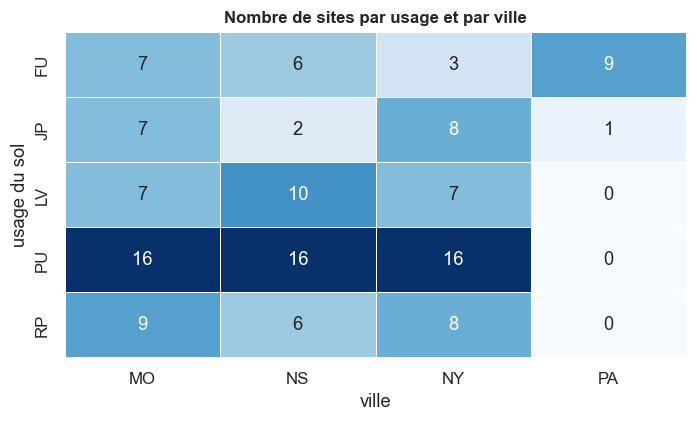

In [11]:
tab_sites = pd.crosstab(df_site.land_use, df_site.city, margins=True, margins_name="Total")
display(tab_sites)

plt.figure(figsize=(6.5, 4))
sns.heatmap(pd.crosstab(df_site.land_use, df_site.city), annot=True, fmt="d",
            cmap="Blues", cbar=False, linewidths=.5)
plt.title("Nombre de sites par usage et par ville")
plt.xlabel("ville")
plt.ylabel("usage du sol")
plt.show()

**Lecture.** Paris ne compte que 10 sites, répartis sur deux usages (9 FU, 1 JP), et aucune modalité LV/PU/RP. Pour Paris, l'effet « ville » et l'effet « usage » sont donc largement confondus : toute comparaison de villes est une comparaison de plans d'échantillonnage différents.

### 4.2 Les indices de diversité

`A` (abondance) est très asymétrique ; `S` (richesse) est un comptage discret ; `H` et `J` sont des indices bornés. `J` porte 81 manquants structurels.

In [12]:
resume = dfa[INDICES].agg(["count", "mean", "std", "min", "median", "max"]).T
resume["asymétrie"] = dfa[INDICES].skew().round(2)
resume.round(2)

,count,mean,std,min,median,max,asymétrie
A,412.0,21.50,56.55,0.00,7.00,593.00,7.09
S,412.0,3.34,2.12,0.00,3.00,13.00,0.70
H,412.0,0.82,0.53,0.00,0.91,1.96,-0.20
J,331.0,0.81,0.19,0.08,0.86,1.00,-1.34


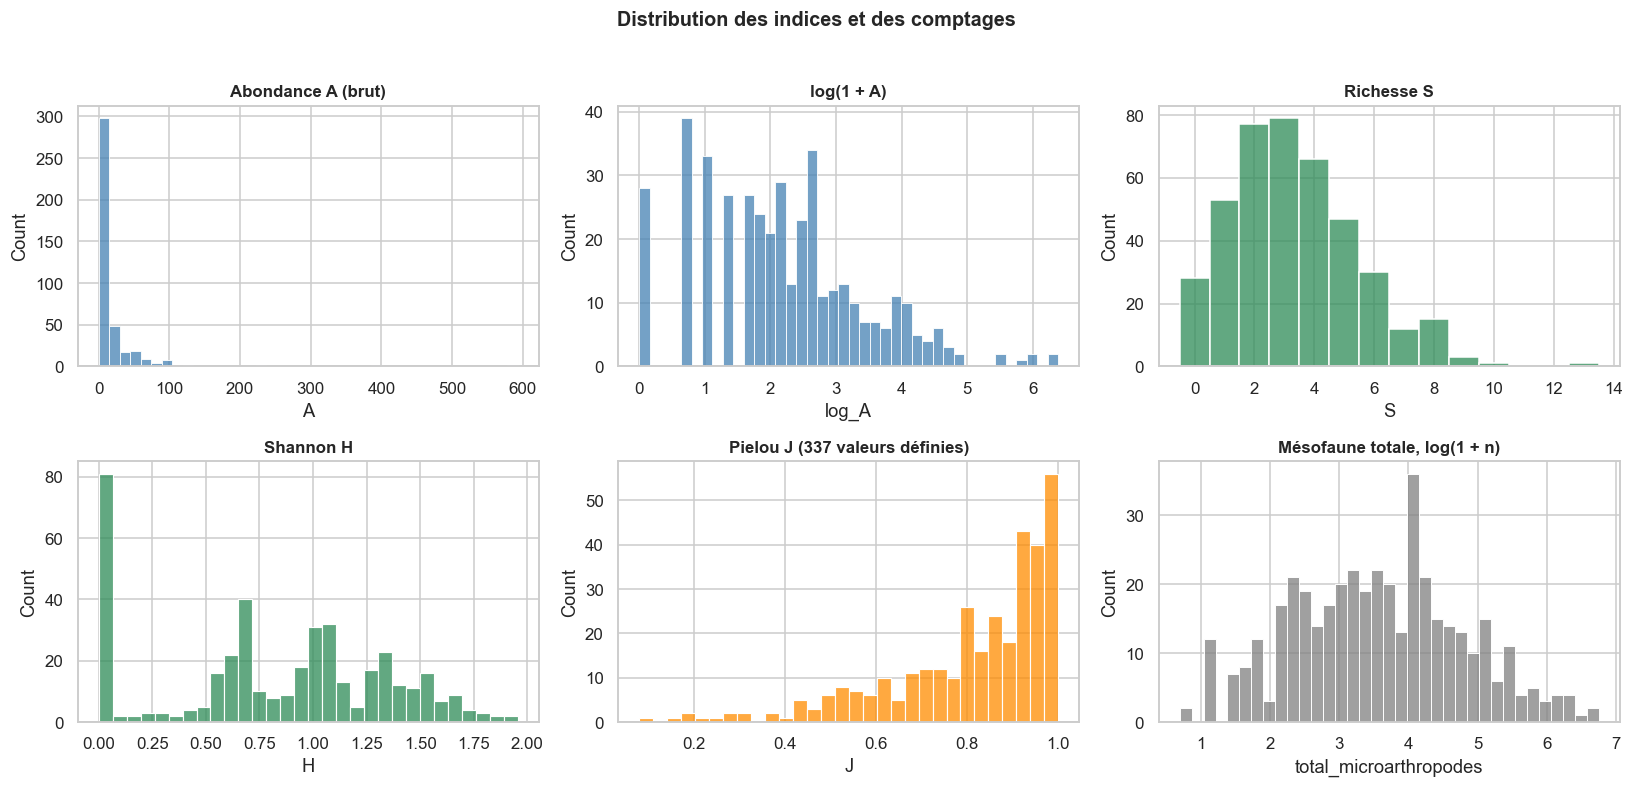

Échantillons sans collembole (A = 0) : 28
Échantillons avec S = 1 (J indéfini) : 53


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

sns.histplot(dfa.A, bins=40, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Abondance A (brut)")

sns.histplot(dfa.log_A, bins=40, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("log(1 + A)")

sns.histplot(dfa.S, bins=np.arange(0, dfa.S.max() + 2) - 0.5, color="seagreen", ax=axes[0, 2])
axes[0, 2].set_title("Richesse S")

sns.histplot(dfa.H, bins=30, color="seagreen", ax=axes[1, 0])
axes[1, 0].set_title("Shannon H")

sns.histplot(dfa.J.dropna(), bins=30, color="darkorange", ax=axes[1, 1])
axes[1, 1].set_title("Pielou J (337 valeurs définies)")

sns.histplot(np.log1p(dfa.total_microarthropodes), bins=35, color="grey", ax=axes[1, 2])
axes[1, 2].set_title("Mésofaune totale, log(1 + n)")

fig.suptitle("Distribution des indices et des comptages", y=1.02, fontsize=13, fontweight="bold")
plt.show()

print("Échantillons sans collembole (A = 0) :", int((dfa.A == 0).sum()))
print("Échantillons avec S = 1 (J indéfini) :", int((dfa.S == 1).sum()))

**Lecture.** L'échelle log est indispensable pour `A` : sans elle, un seul échantillon à 593 individus écrase tout le graphique. `S` et `H` sont eux aussi poussés à droite par une minorité d'échantillons riches, avec une masse à 0–1.

### 4.3 Variabilité intra-site

Si les trois réplicats d'un site se ressemblent, l'essentiel de la variance est **entre** sites, et analyser 412 lignes comme 412 observations indépendantes gonfle artificiellement la précision. On mesure la part de variance expliquée par le site ($\eta^2$).

In [14]:
def eta2(y, g):
    """Part de la variance de y expliquée par les groupes g (0 à 1)."""
    y = pd.Series(np.asarray(y, dtype=float))
    g = pd.Series(np.asarray(g))
    ssb = ((y.groupby(g).transform("mean") - y.mean()) ** 2).sum()
    sst = ((y - y.mean()) ** 2).sum()
    return ssb / sst

eta = pd.Series({v: eta2(dfa[v], dfa.Site) for v in ["A", "S", "H"]})
print("Part de la variance expliquée par le site :")
print((100 * eta).round(1).astype(str).add(" %").to_string())

Part de la variance expliquée par le site :
A    61.7 %
S    49.4 %
H    47.4 %


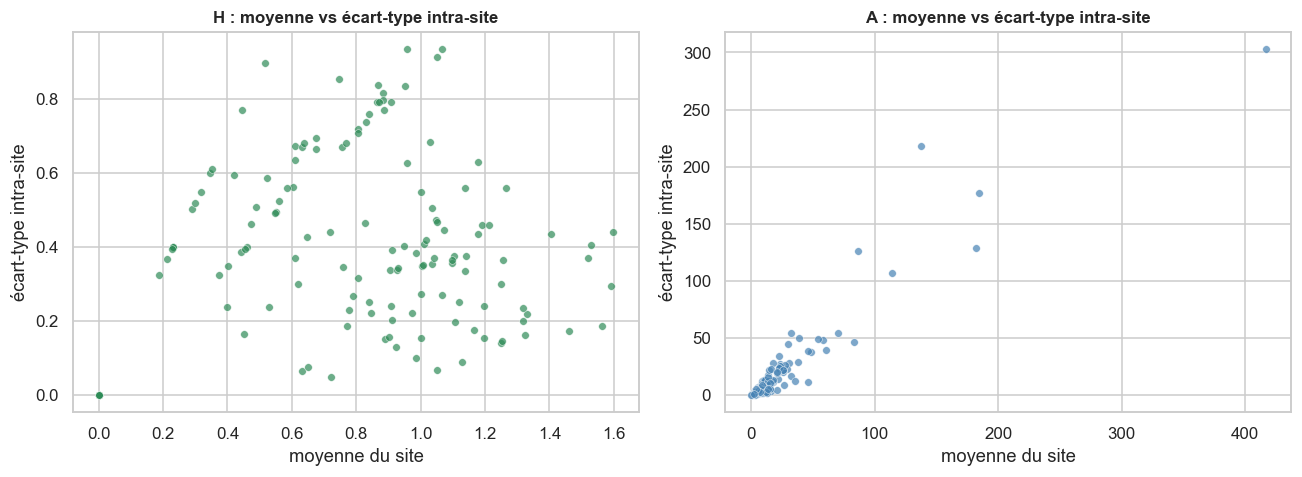

In [15]:
agg_site = dfa.groupby("Site").agg(
    A_m=("A", "mean"), A_sd=("A", "std"),
    H_m=("H", "mean"), H_sd=("H", "std"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=agg_site, x="H_m", y="H_sd", ax=axes[0], s=25, alpha=.7, color="seagreen")
axes[0].set_title("H : moyenne vs écart-type intra-site")
axes[0].set_xlabel("moyenne du site")
axes[0].set_ylabel("écart-type intra-site")

sns.scatterplot(data=agg_site, x="A_m", y="A_sd", ax=axes[1], s=25, alpha=.7, color="steelblue")
axes[1].set_title("A : moyenne vs écart-type intra-site")
axes[1].set_xlabel("moyenne du site")
axes[1].set_ylabel("écart-type intra-site")
plt.show()

**Lecture.** Pour `A`, l'écart-type intra-site croît avec la moyenne (signature d'un comptage de type Poisson surdispersé). Pour `H`, la dispersion intra-site est plus modérée. Dans les deux cas, le site porte une grande partie de l'information : c'est l'argument en faveur de l'agrégation par site pour les analyses sol ↔ diversité.

### 4.4 Les variables de sol

Les échelles sont très différentes : pH ≈ 7,9, fractions granulométriques en g/kg (argile ≈ 190), métaux de 0,3 (Cd) à une centaine (Zn, Pb). On standardise uniquement pour comparer les formes de distribution.

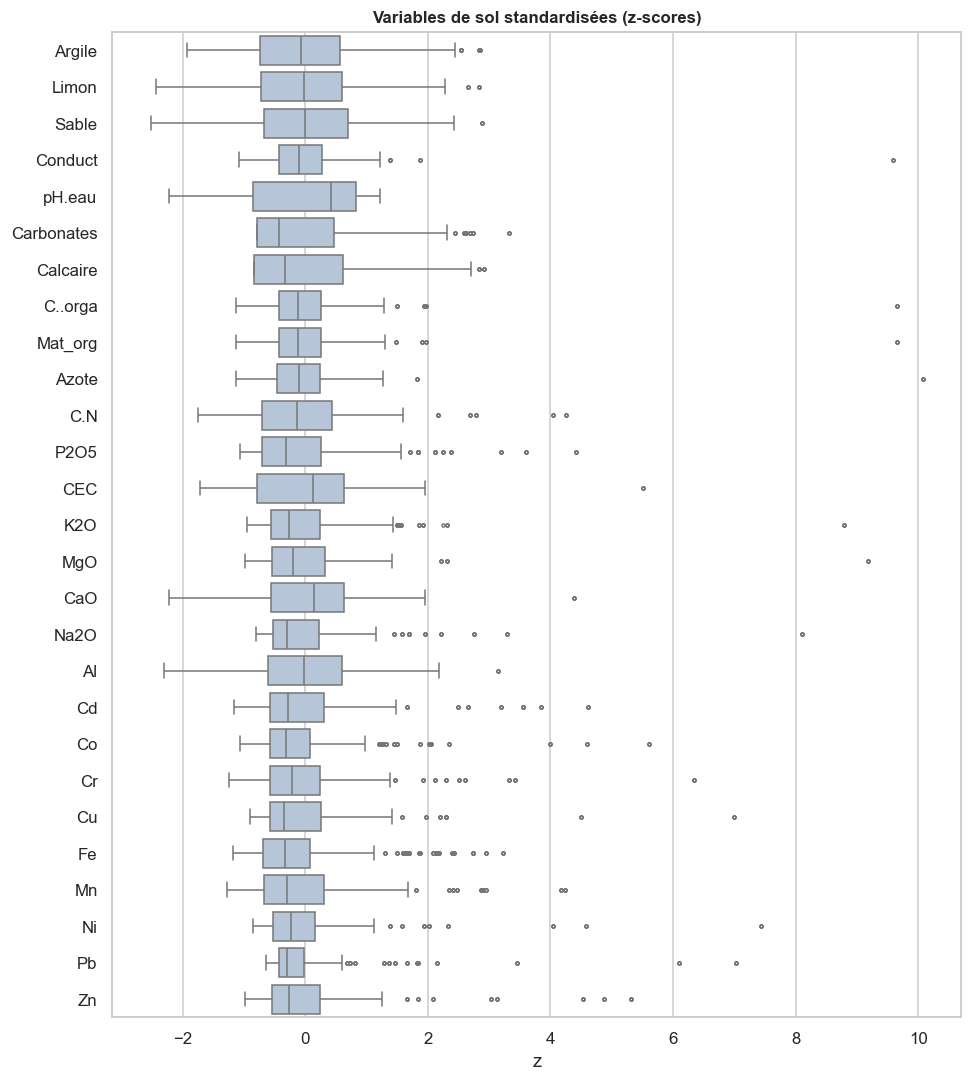

In [16]:
z = dfa[SOL].apply(lambda s: (s - s.mean()) / s.std())

plt.figure(figsize=(9, 10))
sns.boxplot(data=z.melt(var_name="variable", value_name="z"),
            y="variable", x="z", color="lightsteelblue", fliersize=2)
plt.title("Variables de sol standardisées (z-scores)")
plt.xlabel("z")
plt.ylabel("")
plt.show()

**Lecture.** Plusieurs variables ont une queue droite très marquée (Azote, C_orga, Conduct, MgO, K2O, Pb). Ce ne sont pas des erreurs : ce sont les variables à transformer en log pour la modélisation, et celles qui produiront des points leviers (hatvalues, distance de Cook).

## 5. Exploration bivariée

### 5.1 Indices × usage du sol

On compare les distributions par modalité, avec un test de Kruskal-Wallis (non paramétrique, adapté aux distributions asymétriques) et une taille d'effet $\varepsilon^2$. Les p-values ne tiennent pas compte de la pseudo-réplication : elles servent à repérer des contrastes, pas à conclure.

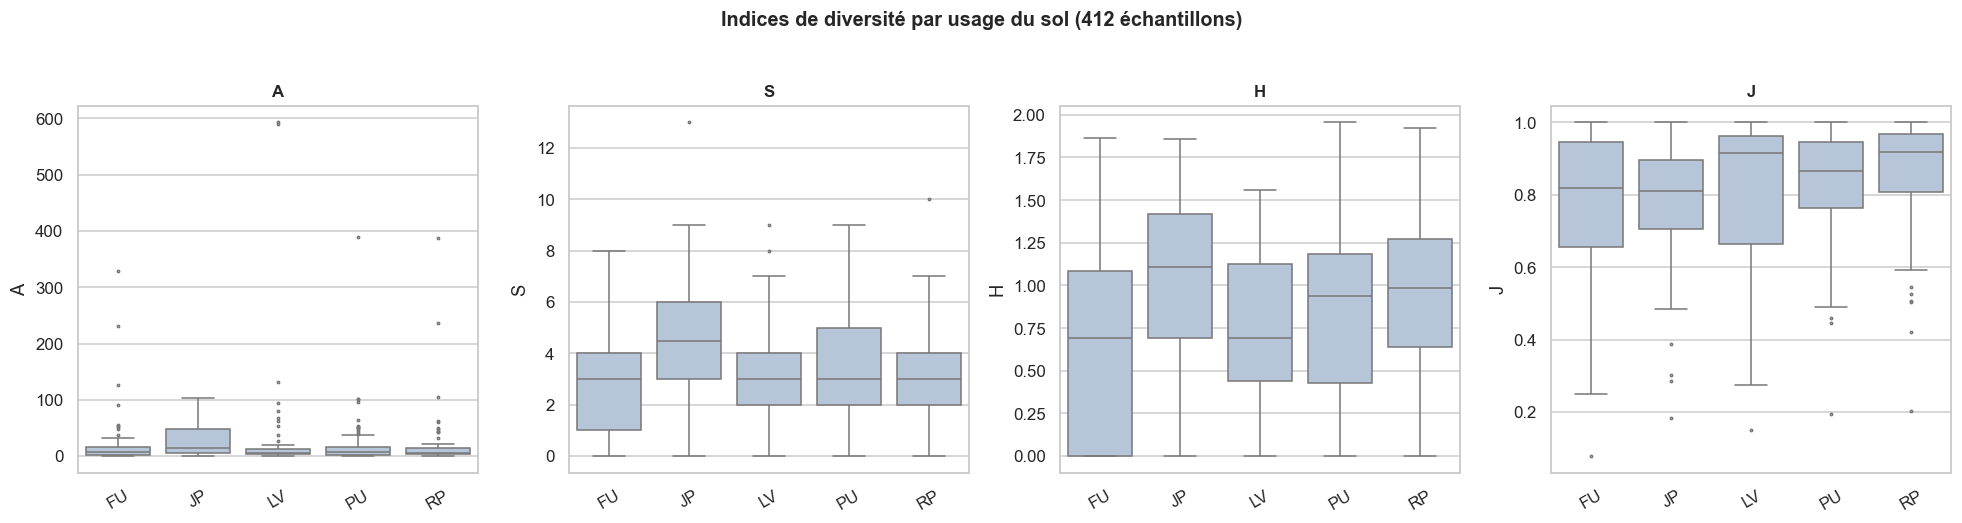

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, v in zip(axes, INDICES):
    sns.boxplot(data=dfa, x="land_use", y=v, color="lightsteelblue", fliersize=1.5, ax=ax)
    ax.set_title(v)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Indices de diversité par usage du sol (412 échantillons)", y=1.03,
             fontsize=13, fontweight="bold")
plt.show()

In [18]:
def epsilon2(groupes, stat_kruskal):
    n = sum(len(g) for g in groupes)
    k = len(groupes)
    return max(0.0, (stat_kruskal - k + 1) / (n - k))

lignes = []
for v in INDICES:
    groupes = [g[v].dropna().values for _, g in dfa.groupby("land_use", observed=True)]
    stat_k, p = stats.kruskal(*groupes)
    lignes.append({"indice": v, "stat_kruskal": stat_k, "p_value": p,
                   "epsilon2": epsilon2(groupes, stat_k), "n": sum(len(g) for g in groupes)})

kruskal_df = pd.DataFrame(lignes)
kruskal_df.round(4)

,indice,stat_kruskal,p_value,epsilon2,n
0,A,14.2314,0.0066,0.0251,412
1,S,19.9176,0.0005,0.0391,412
2,H,14.3590,0.0062,0.0255,412
3,J,12.0043,0.0173,0.0246,331


**Lecture.** Un `epsilon2` faible (< 0,05) signifie que l'usage du sol déplace peu la distribution : les différences visibles sur les boxplots sont surtout de la variabilité résiduelle. C'est cohérent avec l'idée que la diversité dépend d'abord du sol local, pas de l'usage déclaré.

### 5.2 Effet ville et effet usage sont-ils séparables ?

On croise la moyenne de `H` par usage et par ville. Là où une case est vide (ou remplie par 1 seul site), l'effet n'est pas identifiable.

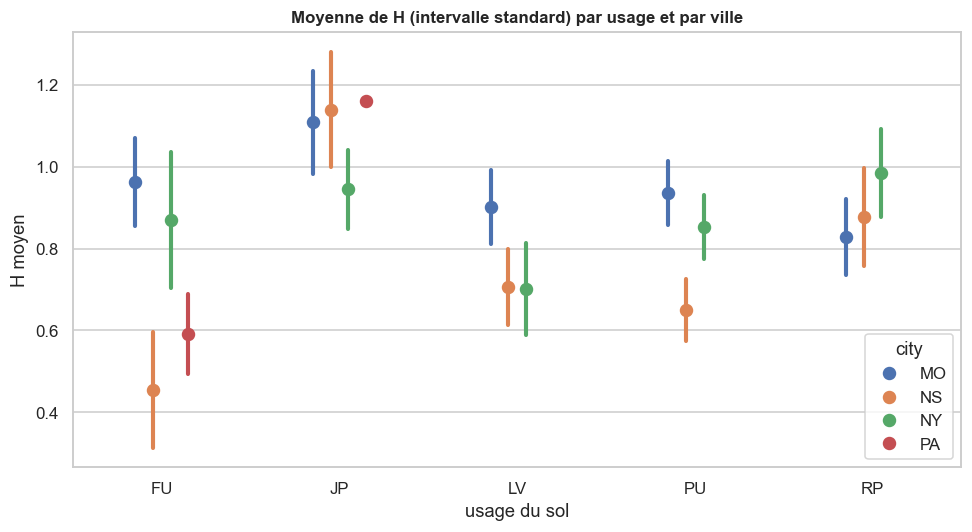

city,MO,NS,NY,PA
land_use,,,,
FU,7,6,3,9
JP,7,2,8,1
LV,7,10,7,0
PU,16,16,16,0
RP,9,6,8,0


In [19]:
plt.figure(figsize=(9, 5))
sns.pointplot(data=dfa, x="land_use", y="H", hue="city", dodge=.3,
              errorbar="se", markers="o", linestyles="", ax=plt.gca())
plt.title("Moyenne de H (intervalle standard) par usage et par ville")
plt.xlabel("usage du sol")
plt.ylabel("H moyen")
plt.show()

pd.crosstab(df_site.land_use, df_site.city)

### 5.3 Relations entre les quatre indices

`H` est une fonction de la distribution des abondances ; `S` est le nombre de taxons ; `A` le total. Ces indices ne sont pas indépendants, ce qui interdit d'en utiliser un comme prédicteur d'un autre (fuite de cible, §7).

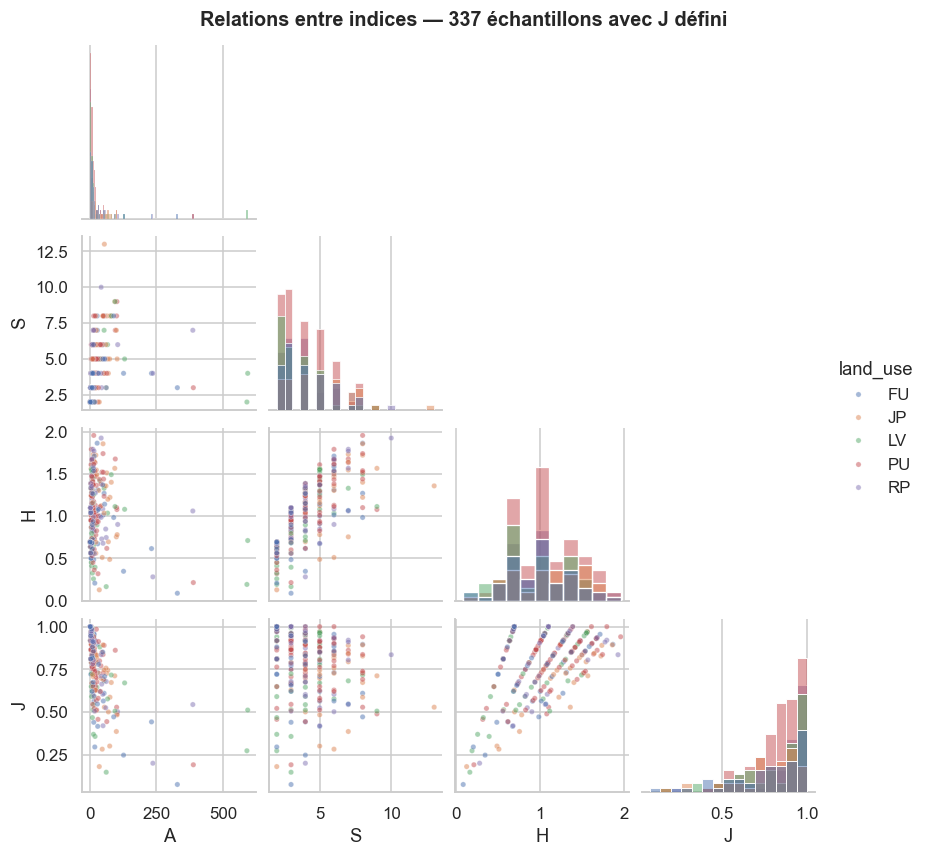

Corrélations de Spearman entre indices (paires complètes) :
      A     S     H     J
A  1.00  0.80  0.55 -0.77
S  0.80  1.00  0.89 -0.31
H  0.55  0.89  1.00  0.25
J -0.77 -0.31  0.25  1.00


In [20]:
sns.pairplot(dfa[INDICES + ["land_use"]].dropna(), hue="land_use", corner=True,
             diag_kind="hist", height=1.9, plot_kws={"s": 12, "alpha": .5})
plt.suptitle("Relations entre indices — 337 échantillons avec J défini", y=1.02,
             fontsize=13, fontweight="bold")
plt.show()

print("Corrélations de Spearman entre indices (paires complètes) :")
print(dfa[INDICES].corr(method="spearman").round(2).to_string())

**Lecture.** `H` est très fortement lié à `S` (rho = 0,89) et à `A` (0,55) : richesse et abondance tirent la diversité. `J` est fortement **anti**-corrélé à `A` (rho = −0,77) — plus la communauté est abondante, plus elle est dominée par quelques espèces, donc moins elle est équilibrée — mais peu lié à `S` (−0,31) et à `H` (0,25). Aucun de ces indices ne peut donc servir d'explicatif aux autres : ils mesurent des choses différentes, construites sur les mêmes comptages. Expliquer `H` par `S` n'apprend rien ; c'est le piège à éviter dans le bloc modélisation.

### 5.4 Indices × variables de sol

Corrélations de Spearman, calculées deux fois : sur les 412 échantillons et sur les 138 sites (moyennes des indices). L'écart entre les deux est la meilleure illustration de la pseudo-réplication.

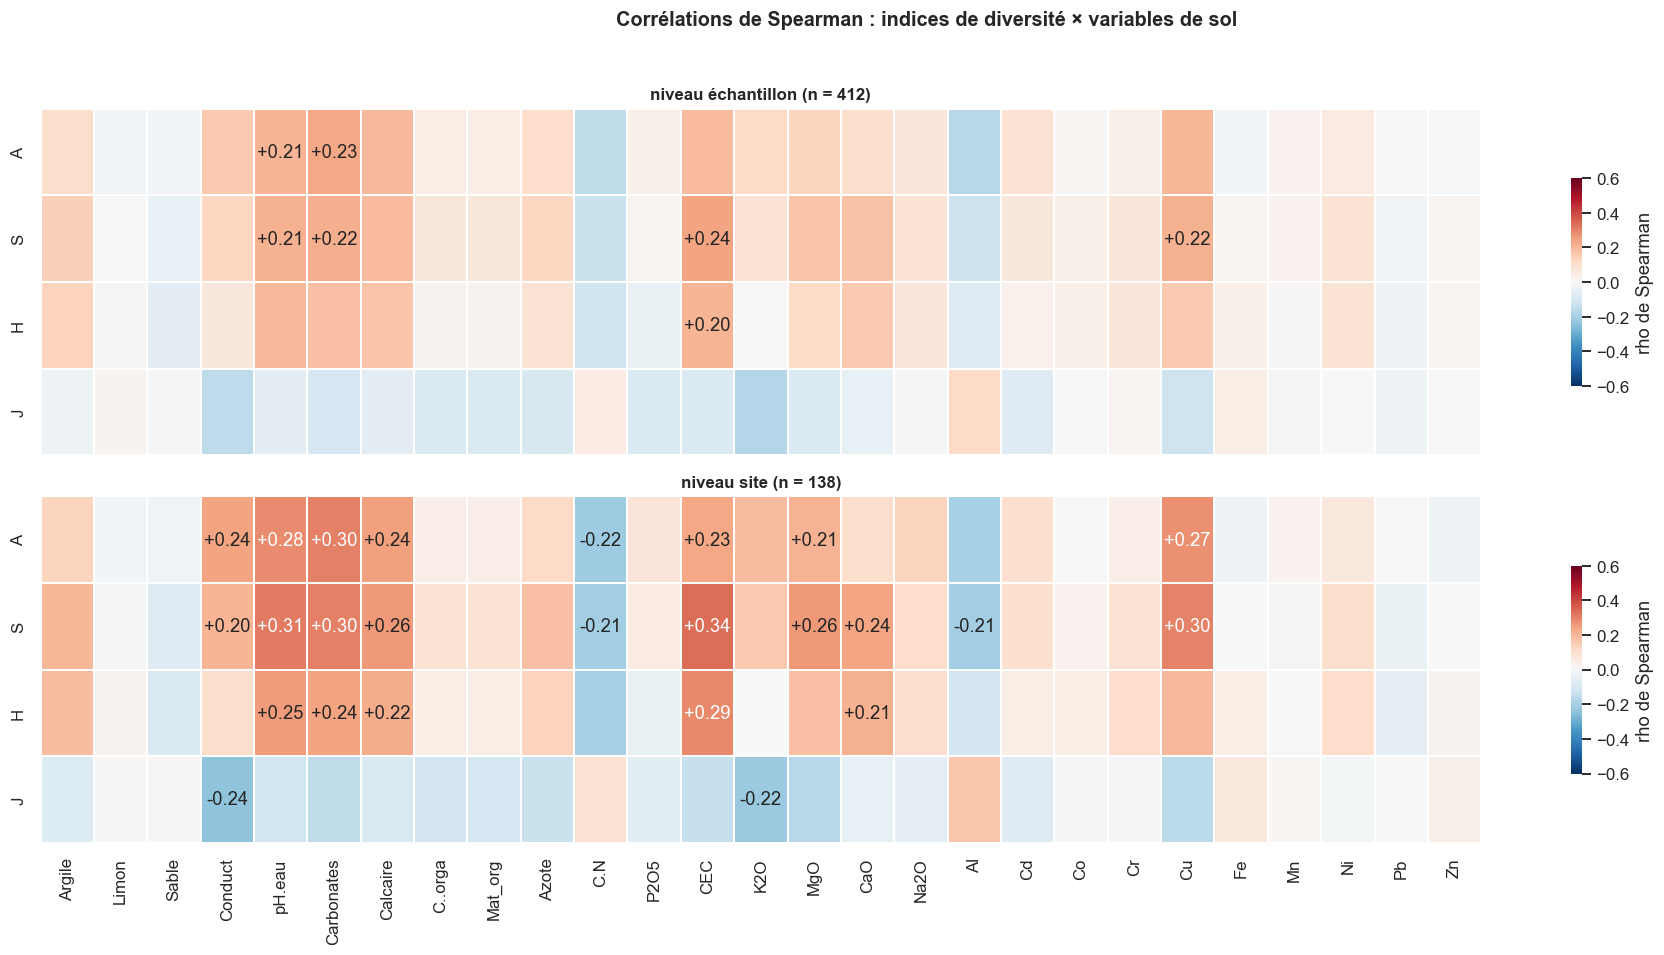

Corrélations avec H, triées par |rho| (niveau site) :
CEC           0.29
pH.eau        0.25
Carbonates    0.24
Calcaire      0.22
CaO           0.21
C.N          -0.20
Cu            0.20
Argile        0.18


In [21]:
cor_ech  = dfa[INDICES + SOL].corr(method="spearman").loc[INDICES, SOL]
cor_site = df_site[INDICES + SOL].corr(method="spearman").loc[INDICES, SOL]

def annoter(mat, seuil=0.20):
    return mat.map(lambda x: f"{x:+.2f}" if abs(x) >= seuil else "").values

fig, axes = plt.subplots(2, 1, figsize=(17, 8.5), sharex=True)
for ax, mat, titre in [
        (axes[0], cor_ech,  "niveau échantillon (n = 412)"),
        (axes[1], cor_site, "niveau site (n = 138)")]:
    sns.heatmap(mat, annot=annoter(mat), fmt="", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6,
                linewidths=.3, ax=ax, cbar_kws={"shrink": .6, "label": "rho de Spearman"})
    ax.set_title(titre)
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylabel("")
plt.suptitle("Corrélations de Spearman : indices de diversité × variables de sol",
             y=1.02, fontsize=13, fontweight="bold")
plt.show()

print("Corrélations avec H, triées par |rho| (niveau site) :")
print(cor_site.loc["H"].sort_values(key=np.abs, ascending=False).head(8).round(2).to_string())

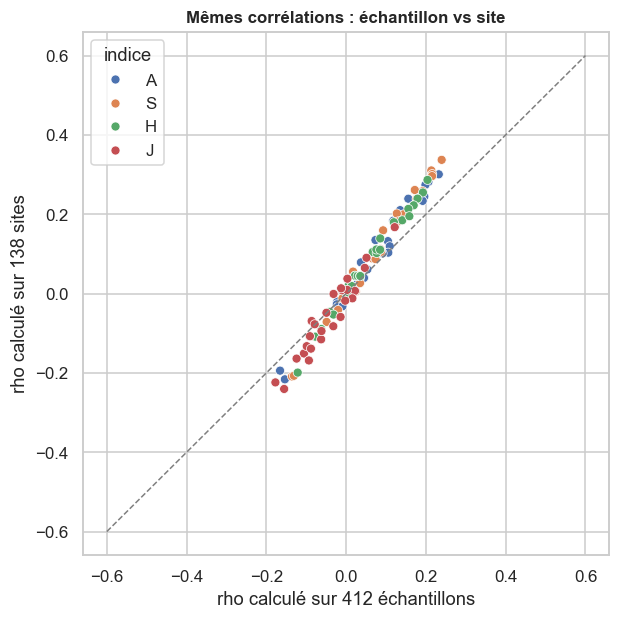

Écart absolu moyen entre les deux niveaux : 0.036


In [22]:
comp = pd.DataFrame({
    "indice": np.repeat(cor_ech.index.values, len(SOL)),
    "variable": np.tile(SOL, len(INDICES)),
    "r_echantillon": cor_ech.values.ravel(),
    "r_site": cor_site.loc[cor_ech.index, SOL].values.ravel(),
})

plt.figure(figsize=(5.8, 5.8))
sns.scatterplot(data=comp, x="r_echantillon", y="r_site", hue="indice", s=35)
plt.plot([-.6, .6], [-.6, .6], color="grey", ls="--", lw=1)
plt.title("Mêmes corrélations : échantillon vs site")
plt.xlabel("rho calculé sur 412 échantillons")
plt.ylabel("rho calculé sur 138 sites")
plt.show()

print("Écart absolu moyen entre les deux niveaux :",
      round((comp.r_echantillon - comp.r_site).abs().mean(), 3))

**Lecture.** Les deux matrices sont presque superposables : l'écart absolu moyen n'est que de **0,036** et le plus grand de **0,098** (CEC × `S`). La diversité est donc bien portée par le site ; la pseudo-réplication ne déforme pas les corrélations, elle gonfle la **précision apparente**. Un rho de 0,20 passe de p ≈ 0,02 avec 138 sites à p ≈ 4·10⁻⁵ avec 412 lignes, alors que le nombre d'observations indépendantes n'a pas changé.

Les corrélations restent modestes (|rho| < 0,35) : le sol seul explique peu la diversité, et les relations ne sont pas linéaires.

### 5.5 Zoom sur les relations les plus fortes avec H

Nuages de points avec une courbe LOWESS (tendance locale, sans forme imposée), pour voir si la relation est monotone ou non.

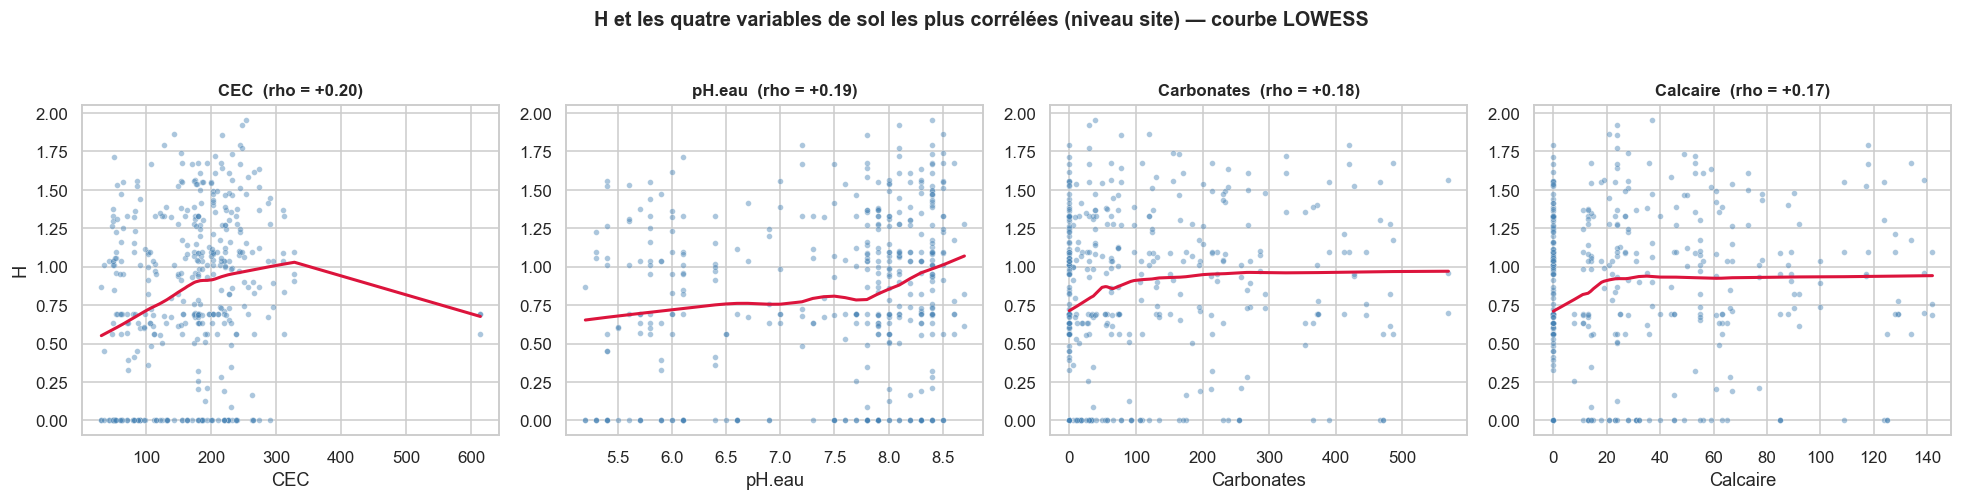

In [23]:
top4 = cor_site.loc["H"].abs().sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, v in zip(axes, top4):
    sub = dfa[[v, "H"]].dropna()
    sns.scatterplot(data=sub, x=v, y="H", s=14, alpha=.45, color="steelblue", ax=ax)
    liss = lowess(sub["H"].values, sub[v].values, frac=.6, return_sorted=True)
    ax.plot(liss[:, 0], liss[:, 1], color="crimson", lw=2)
    rho = stats.spearmanr(sub[v], sub["H"]).statistic
    ax.set_title(f"{v}  (rho = {rho:+.2f})")
    ax.set_ylabel("H" if ax is axes[0] else "")
fig.suptitle("H et les quatre variables de sol les plus corrélées (niveau site) — courbe LOWESS",
             y=1.03, fontsize=13, fontweight="bold")
plt.show()

In [24]:
lignes = []
for v in SOL:
    sub = df_site[[v, "H"]].dropna()
    rho, p = stats.spearmanr(sub[v], sub["H"])
    lignes.append({"variable": v, "rho": rho, "p_value": p})

cor_h = pd.DataFrame(lignes).sort_values("p_value").reset_index(drop=True)
m = len(cor_h)
q_brut = (cor_h.p_value * m / (cor_h.index + 1)).values
cor_h["q_BH"] = np.clip(np.minimum.accumulate(q_brut[::-1])[::-1], 0, 1)
cor_h["significatif (q < 0,05)"] = cor_h.q_BH < 0.05

print(f"{int(cor_h['significatif (q < 0,05)'].sum())} variables sur {m} restent significatives "
      "après correction de Benjamini-Hochberg (27 tests).")
cor_h.reindex(cor_h.rho.abs().sort_values(ascending=False).index).head(8).round(4)

3 variables sur 27 restent significatives après correction de Benjamini-Hochberg (27 tests).


,variable,rho,p_value,q_BH,"significatif (q < 0,05)"
0,CEC,0.2865,0.0007,0.0177,True
1,pH.eau,0.2548,0.0026,0.0345,True
2,Carbonates,0.2394,0.0047,0.0422,True
3,Calcaire,0.2225,0.0087,0.0589,False
4,CaO,0.2135,0.0119,0.0645,False
5,C.N,-0.1992,0.0192,0.0844,False
6,Cu,0.1951,0.0219,0.0844,False
7,Argile,0.1848,0.0300,0.1014,False


**Lecture.** Après correction de Benjamini-Hochberg, **3 variables sur 27** restent significativement liées à `H` au seuil 5 % : la CEC, le pH et les carbonates. Les associations plus faibles (calcaire, CaO, C/N, cuivre, argile) ne se distinguent plus du bruit une fois la multiplicité prise en compte. C'est exactement le risque signalé par la note du §7 : 27 tests bruts produisent mécaniquement des « découvertes ».

## 6. Structures multivariées

### 6.1 Corrélations entre variables de sol

Le but n'est pas de commenter les 351 paires, mais d'identifier les **redondances** qui poseront problème en régression (multicolinéarité).

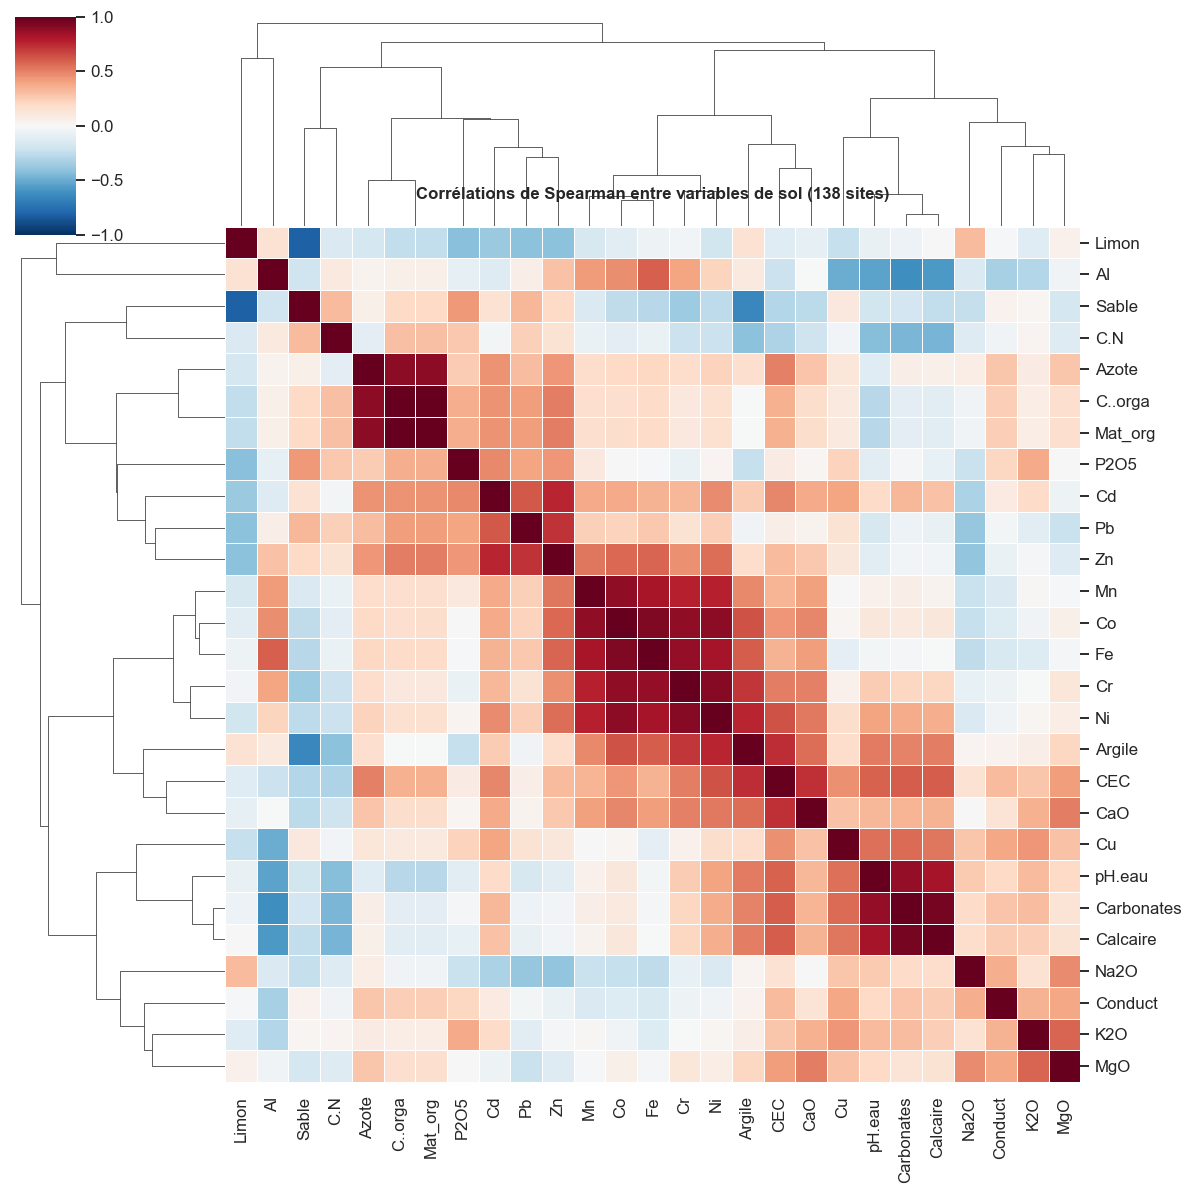

Les dix paires les plus corrélées :
                       rho
C..orga    Mat_org   1.000
Carbonates Calcaire  0.956
Co         Fe        0.932
Cr         Ni        0.914
C..orga    Azote     0.897
Mat_org    Azote     0.897
Co         Ni        0.896
           Mn        0.886
           Cr        0.884
Cr         Fe        0.879


In [25]:
corr_sol = df_site[SOL].corr(method="spearman")

g = sns.clustermap(corr_sol, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                   figsize=(11, 11), linewidths=.4, cbar_kws={"shrink": .6})
g.ax_heatmap.set_title("Corrélations de Spearman entre variables de sol (138 sites)", pad=18)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
plt.show()

triangle = corr_sol.where(np.triu(np.ones(corr_sol.shape), 1).astype(bool)).stack()
triangle = triangle.sort_values(key=np.abs, ascending=False)
print("Les dix paires les plus corrélées :")
print(triangle.head(10).round(3).to_frame("rho").to_string())

**Lecture.** Quatre familles ressortent, et chacune correspond à une relation connue :

- **pH – carbonates – calcaire** : r de 0,83 à 0,96 entre `pH.eau`, `Carbonates` et `Calcaire` ;
- **matière organique** : `C..orga` – `Azote` = 0,90, et `Mat_org` est un multiple presque exact de `C..orga` ;
- **texture** : `Limon` – `Sable` = −0,82 et `Argile` – `Sable` = −0,65 (les fractions se partagent 1000) ; `Argile` et `Limon` ne sont liés qu'à +0,15 ;
- **deux familles de métaux** : `Co` – `Fe` – `Ni` – `Cr` – `Mn` (0,82 à 0,93, origine géologique probable) et `Pb` – `Zn` – `Cd` (0,72 à 0,76, pollution probable). `Cu` est à part, plus corrélé au pH (0,55).

Conséquence pour la régression : ces blocs sont redondants, il faudra en garder un représentant par famille (§7).

### 6.2 ACP du sol

ACP normée (variables standardisées) sur les 138 sites. Elle résume la structure du sol et permet de projeter les sites dans un plan lisible.

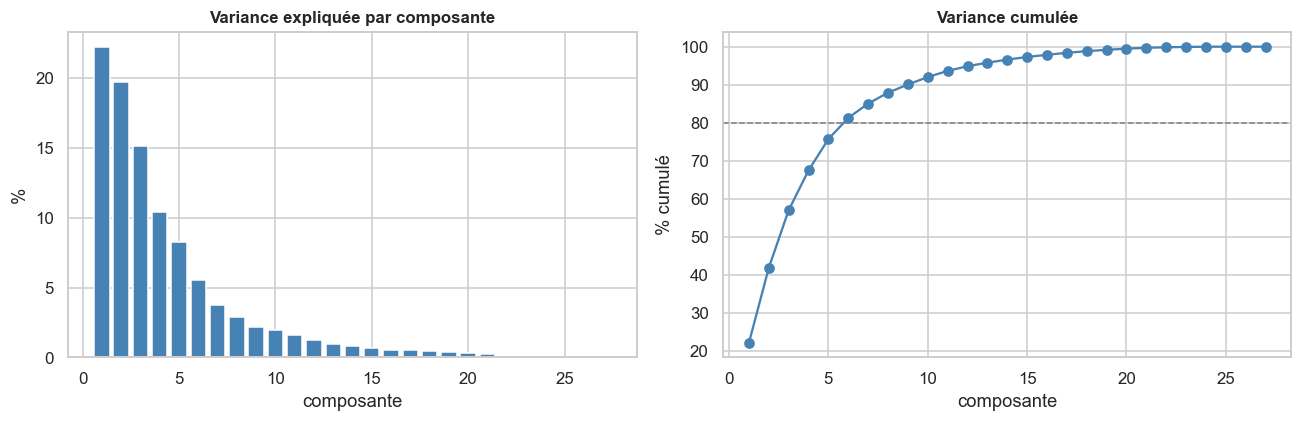

Variance expliquée : PC1 22.2 %, PC2 19.7 %, PC3 15.1 %, PC4 10.4 %, PC5 8.2 %
Cumul PC1-PC2 : 41.9 % — PC1-PC3 : 57.0 %
PC1 : Co (+0.33), Cr (+0.32), Ni (+0.32), Fe (+0.31), CEC (+0.30), Mn (+0.30)
PC2 : Mat_org (+0.30), C..orga (+0.30), Conduct (+0.29), Azote (+0.28), P2O5 (+0.28), Al (-0.25)
PC3 : Calcaire (+0.42), Carbonates (+0.42), pH.eau (+0.32), Al (-0.28), C.N (-0.26), CEC (+0.22)


In [26]:
scaler = StandardScaler()
Zs = scaler.fit_transform(df_site[SOL])
pca = PCA()
scores = pca.fit_transform(Zs)
evr = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(evr) + 1), evr * 100, color="steelblue")
axes[0].set_title("Variance expliquée par composante")
axes[0].set_xlabel("composante")
axes[0].set_ylabel("%")

axes[1].plot(range(1, len(evr) + 1), np.cumsum(evr) * 100, marker="o", color="steelblue")
axes[1].axhline(80, color="grey", ls="--", lw=1)
axes[1].set_title("Variance cumulée")
axes[1].set_xlabel("composante")
axes[1].set_ylabel("% cumulé")
plt.show()

print("Variance expliquée :", ", ".join(f"PC{i+1} {100*e:.1f} %" for i, e in enumerate(evr[:5])))
print(f"Cumul PC1-PC2 : {100*evr[:2].sum():.1f} % — PC1-PC3 : {100*evr[:3].sum():.1f} %")

charges = pd.DataFrame(pca.components_[:3].T, index=SOL, columns=["PC1", "PC2", "PC3"])
for pc in ["PC1", "PC2", "PC3"]:
    top = charges[pc].sort_values(key=np.abs, ascending=False).head(6)
    print(f"{pc} : " + ", ".join(f"{v} ({x:+.2f})" for v, x in top.items()))

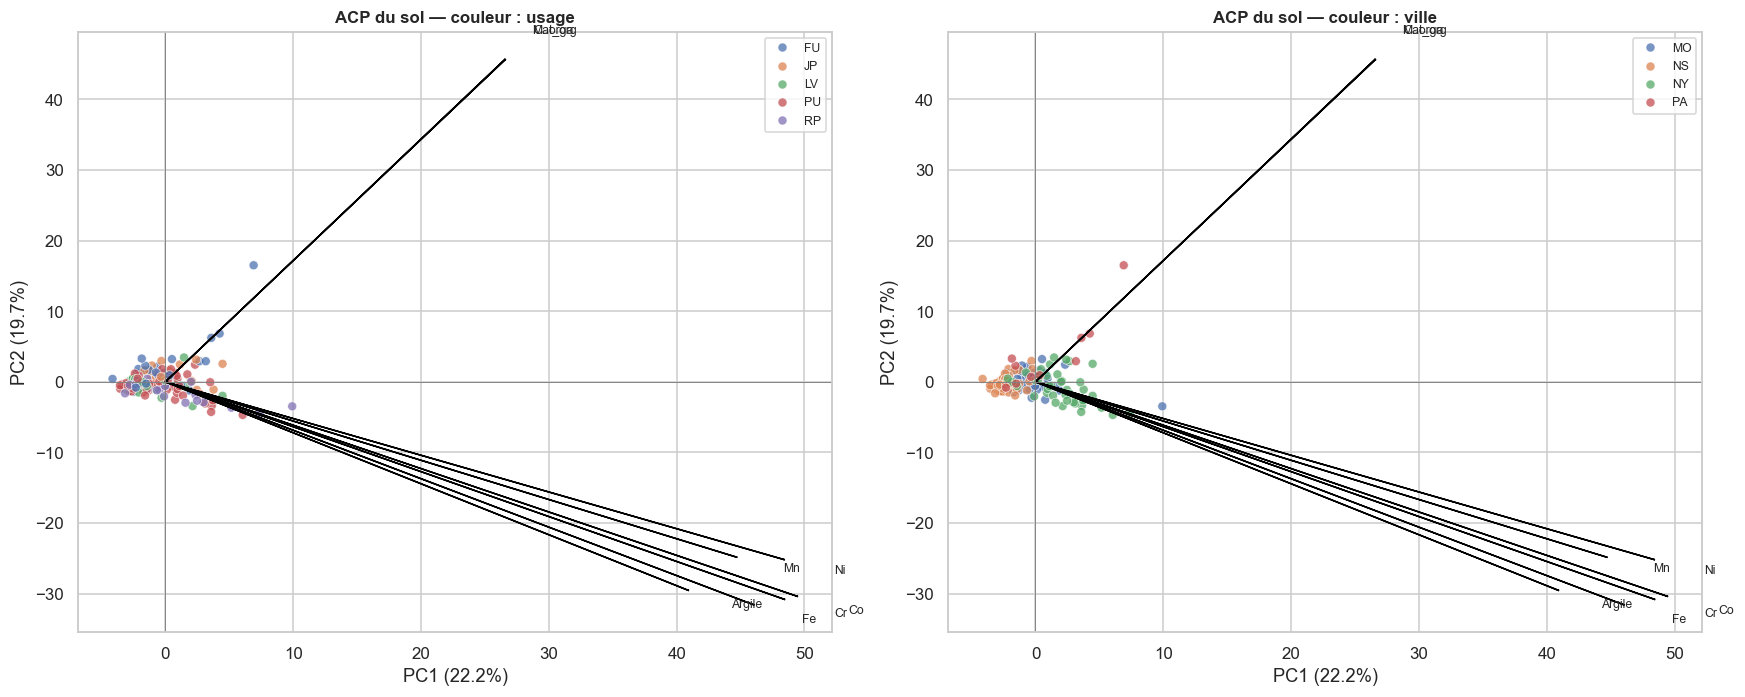

In [27]:
def biplot(ax, couleur, titre):
    sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=couleur, s=35, alpha=.75,
                    palette="deep", ax=ax)
    facteur = 3.0 * np.abs(scores[:, :2]).max() / np.abs(charges[["PC1", "PC2"]].values).max()
    principales = (charges[["PC1", "PC2"]]
                   .assign(norme=lambda d: d.PC1 ** 2 + d.PC2 ** 2)
                   .nlargest(8, "norme").index)
    for v in principales:
        x, y = charges.loc[v, "PC1"] * facteur, charges.loc[v, "PC2"] * facteur
        ax.arrow(0, 0, x, y, color="black", width=.002, head_width=.05,
                 length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, v, fontsize=8)
    ax.axhline(0, color="grey", lw=.6)
    ax.axvline(0, color="grey", lw=.6)
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
    ax.set_title(titre)
    ax.legend(fontsize=8, title=None, loc="best")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
biplot(axes[0], df_site.land_use, "ACP du sol — couleur : usage")
biplot(axes[1], df_site.city, "ACP du sol — couleur : ville")
plt.show()

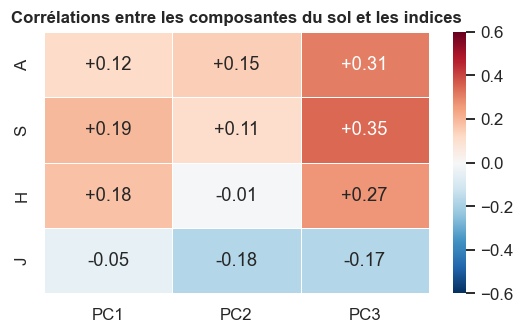

In [28]:
cor_pc = pd.DataFrame(
    {f"PC{i+1}": df_site[INDICES].corrwith(pd.Series(scores[:, i], index=df_site.index),
                                           method="spearman")
     for i in range(3)},
)

plt.figure(figsize=(5, 3.2))
sns.heatmap(cor_pc, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6,
            linewidths=.5)
plt.title("Corrélations entre les composantes du sol et les indices")
plt.xlabel("")
plt.ylabel("")
plt.show()

**Lecture.** Les trois premières composantes (57 % de la variance) ont un sens identifiable : PC1 (22 %) est un **axe métallique** (Co, Cr, Ni, Fe, Mn, CEC tous du même côté) ; PC2 (20 %) porte la **matière organique et la conductivité** (Mat_org, C_orga, Conduct, Azote, P2O5) ; PC3 (15 %) est l'**axe pH – carbonates – calcaire**. Les sites ne se regroupent pas nettement par ville : la structure du sol varie à l'intérieur de chaque ville, ce qui rend l'effet ville difficile à isoler (cohérent avec le plan déséquilibré du §4.1). Les corrélations indices × composantes restent faibles, avec un maximum de **0,35** (`S` sur PC3, l'axe pH-carbonates ; sur ce même axe, `A` ≈ 0,31 et `H` ≈ 0,27 ; `J` reste sous 0,20 en valeur absolue). Le sol n'explique donc qu'une partie de la diversité.

---

## 7. Ce qu'il faut corriger avant de modéliser

> **Ce qu'il faut corriger avant de modéliser**
>
> **Pseudo-réplication.** Le fichier a 1 ligne par échantillon, mais le sol est mesuré par site (3 réplicats par site, sauf un site PA_JP qui n'en a qu'un). Les erreurs d'un même site sont corrélées, donc (H2) est violée et les p-valeurs seraient trop optimistes avec n = 418. Il faut moyenner H par site (n = 140).
>
> **Deux sites au sol imputé.** BISES_NY_PU_GOD_RU (médiane des parcs NY) et BISES_NY_PU_PEP_RU (copie de PEP_P) n'ont pas de vraies mesures. Je recommande de les retirer avec `sol_impute == "non"`, ce qui laisse n = 138 ; les garder créerait un doublon exact de X.
>
> **Fuite de cible.** Ne jamais mettre A, S, J ni total_microarthropodes en explicatives de H : cor(H, S) = 0,84 et total_microarthropodes = A + Acari_total + Other exactement. Les colonnes Acari sont aussi liées entre elles (Acari_total = somme des trois).
>
> **Colinéarité très forte (chap. 8.2).** κ = 3,0·10⁶ pour un seuil de 500, et VIF max ≈ 246 000 pour un seuil de 10. Les causes sont les relations quasi exactes attendues :
> - Argile + Limon + Sable ≈ 1000 ;
> - Mat_org ≈ 1,73 × C_orga ;
> - C/N = C_orga / Azote ;
> - Carbonates ~ Calcaire (r = 0,94).
>
> Il faut retirer les variables une à une (Mat_org, Sable, Azote, puis VIF itératif), idéalement avec l'avis d'experts du domaine.
>
> **Plan déséquilibré pour city.** Paris n'a que 10 sites, sur 2 usages seulement (FU, JP) : l'effet ville et l'effet usage y sont confondus.
>
> **Variables de sol très asymétriques.** Azote, C_orga, Conduct, MgO, K2O et Pb ont une skewness entre 4,7 et 7,4. Il y aura des points leviers à surveiller (hatvalues, Cook) ; les résidus partiels (crPlots) diront si un log est utile.

### 7.1 Vérification point par point

In [29]:
print("1) PSEUDO-RÉPLICATION")
print(f"   {len(df)} échantillons pour {df.Site.nunique()} sites ;",
      "réplicats par site :", df.groupby('Site').size().value_counts().sort_index().to_dict())
print(f"   Part de la variance de H expliquée par le site : {eta2(dfa.H, dfa.Site):.1%}")
print("   -> analyser 412 lignes comme indépendantes gonfle la précision.\n")

print("2) SITES AU SOL IMPUTÉ")
print(df[df.sol_impute != "non"][["Site", "sol_impute", "city", "land_use"]]
      .drop_duplicates().to_string(index=False))
pep_p  = df.loc[df.Site == "BISES_NY_PU_PEP_P",  SOL].iloc[0]
pep_ru = df.loc[df.Site == "BISES_NY_PU_PEP_RU", SOL].iloc[0]
print("   PEP_RU identique à PEP_P sur les 27 variables :", bool((pep_p.values == pep_ru.values).all()))
print("   Après filtre sol_impute == 'non' :", len(dfa), "échantillons,", dfa.Site.nunique(), "sites\n")

print("3) FUITE DE CIBLE")
print("   Corrélations (Pearson) avec H :")
print(dfa[["A", "S", "J", "Acari_total", "total_microarthropodes"]]
      .corrwith(dfa["H"]).round(2).to_frame("r avec H").to_string())
print("   total_micro - (A + Acari_total + Other) : écart max =",
      (df.total_microarthropodes - (df.A + df.Acari_total + df.Other_microarthropodes)).abs().max())
print("   Acari_total - (3 colonnes Acari) : écart max =",
      (df.Acari_total - (df.Acari_Gamasides + df.Acari_Oribates + df.Acari_others)).abs().max(), "\n")

print("4) COLINÉARITÉ")
X_sol = add_constant(df_site[SOL])
X_z   = add_constant(pd.DataFrame(StandardScaler().fit_transform(df_site[SOL]), columns=SOL))
print(f"   Conditionnement sol + constante   : {np.linalg.cond(X_sol.values):.2e}   (seuil indicatif 500)")
print(f"   Conditionnement sol standardisé   : {np.linalg.cond(X_z.values):.2e}")
vif = pd.Series([variance_inflation_factor(X_sol.values, i) for i in range(1, X_sol.shape[1])],
                index=SOL).sort_values(ascending=False)
print("   VIF les plus élevés :")
print(vif.head(8).round(0).to_string())
texte = df[["Argile", "Limon", "Sable"]].sum(axis=1)
print("   Argile + Limon + Sable : de", f"{texte.min():.1f}", "à", f"{texte.max():.1f}")
print("   Mat_org / C.orga (médiane) :", round((df.Mat_org / df["C..orga"]).median(), 2),
      "| corrélation :", round(df[["Mat_org", "C..orga"]].corr().iloc[0, 1], 4))
print("   corr(C.orga / Azote, C.N) :",
      round(df[["C.N"]].assign(ratio=df["C..orga"] / df.Azote).corr().iloc[0, 1], 4))
print("   corr(Carbonates, Calcaire) :", round(df[["Carbonates", "Calcaire"]].corr().iloc[0, 1], 3), "\n")

print("5) PLAN DÉSÉQUILIBRÉ")
print(pd.crosstab(df_site.land_use, df_site.city, margins=True, margins_name="Total").to_string(), "\n")

print("6) ASYMÉTRIE")
print(df[["Azote", "C..orga", "Conduct", "MgO", "K2O", "Pb"]].skew().round(2).to_string())

1) PSEUDO-RÉPLICATION
   418 échantillons pour 140 sites ; réplicats par site : {1: 1, 3: 139}
   Part de la variance de H expliquée par le site : 47.4%
   -> analyser 412 lignes comme indépendantes gonfle la précision.

2) SITES AU SOL IMPUTÉ
              Site       sol_impute city land_use
BISES_NY_PU_GOD_RU mediane_NY_PU_RU   NY       PU
BISES_NY_PU_PEP_RU   variante_soeur   NY       PU
   PEP_RU identique à PEP_P sur les 27 variables : True
   Après filtre sol_impute == 'non' : 412 échantillons, 138 sites

3) FUITE DE CIBLE
   Corrélations (Pearson) avec H :
                        r avec H
A                           0.03
S                           0.84
J                           0.41
Acari_total                 0.10
total_microarthropodes      0.10
   total_micro - (A + Acari_total + Other) : écart max = 0
   Acari_total - (3 colonnes Acari) : écart max = 0 

4) COLINÉARITÉ
   Conditionnement sol + constante   : 1.46e+06   (seuil indicatif 500)
   Conditionnement sol standardi

### 7.2 Ce que je retrouve exactement

| Point de la note | Résultat du code | Statut |
|---|---|---|
| VIF max ≈ 246 000 | **245 981** (Mat_org), sol + constante | identique |
| κ ≈ 3,0·10⁶ | **1,46·10⁶** (sol + constante), **1,47·10⁶** avec les facteurs | même ordre de grandeur ; l'écart vient du design et de l'échelle retenus |
| cor(H, S) = 0,84 | **0,844** échantillons, **0,870** sites | identique |
| `total_micro = A + Acari_total + Other` | écart max **0** | identique |
| `Acari_total` = somme des trois | écart max **0** | identique |
| Mat_org ≈ 1,73 × C_orga | ratio médian **1,73**, r = **1,0000** | identique |
| C/N = C_orga / Azote | r = **0,9994**, écarts d'arrondi jusqu'à 0,64 | relation quasi exacte, pas une identité |
| Argile+Limon+Sable = 1000 | de **971,5 à 1001** | quasi-colinéarité, pas une identité exacte |
| Carbonates ~ Calcaire (0,94) | r = **0,943** (Spearman 0,956) | identique |
| Paris : 10 sites, 2 usages | **9 FU + 1 JP** | identique |
| Skewness 4,7–7,4 | **4,77 à 7,55** | cohérent (Azote 7,55) |
| 138 sites après retrait | **138 sites / 412 échantillons** | identique |

Deux nuances à garder en tête :

- Le conditionnement dépend de l'échelle et des colonnes retenues (avec ou sans facteurs, avec ou sans les indices). Le VIF, lui, ne dépend pas de l'échelle et concorde exactement.
- `Argile + Limon + Sable` n'est pas **exactement** 1000 (mesures arrondies). La colinéarité est donc très forte, pas parfaite : retirer `Sable` reste justifié, mais le choix peut se discuter selon l'usage (texture en trois fractions ou deux).

### 7.3 Retrait séquentiel des variables colinéaires

L'algorithme retire à chaque étape la variable de VIF maximal jusqu'à passer sous le seuil de 10. C'est une **proposition mécanique** : l'ordre final entre `C_orga`, `Azote` et `C.N` est un choix d'interprétation, à valider par le bloc modélisation.

In [30]:
def vif_sequentiel(X, seuil=10):
    """Retire itérativement la variable de VIF maximal. Retourne (colonnes gardées, journal)."""
    cols = list(X.columns)
    journal = []
    while len(cols) > 1:
        M = add_constant(X[cols])
        v = pd.Series([variance_inflation_factor(M.values, i) for i in range(1, M.shape[1])],
                      index=cols)
        if v.max() <= seuil:
            break
        pire = v.idxmax()
        journal.append({"variable retirée": pire, "VIF avant retrait": v.max(),
                        "variables restantes": len(cols)})
        cols.remove(pire)
    return cols, pd.DataFrame(journal)

explicatives, journal_vif = vif_sequentiel(df_site[SOL], seuil=10)
print("Journal des retraits :")
display(journal_vif.round(1))

M_final = add_constant(df_site[explicatives])
vif_final = pd.Series([variance_inflation_factor(M_final.values, i) for i in range(1, M_final.shape[1])],
                      index=explicatives)
print(f"VIF maximal après retraits : {vif_final.max():.2f} (seuil 10)")
print(f"Il reste {len(explicatives)} variables explicatives candidates :")
print(explicatives)

Journal des retraits :


,variable retirée,VIF avant retrait,variables restantes
0,Mat_org,245981.0,27
1,Sable,82299.1,26
2,C..orga,217.4,25
3,Co,33.8,24
4,CEC,26.5,23
5,Carbonates,13.2,22
6,Cr,10.9,21


VIF maximal après retraits : 7.57 (seuil 10)
Il reste 20 variables explicatives candidates :
['Argile', 'Limon', 'Conduct', 'pH.eau', 'Calcaire', 'Azote', 'C.N', 'P2O5', 'K2O', 'MgO', 'CaO', 'Na2O', 'Al', 'Cd', 'Cu', 'Fe', 'Mn', 'Ni', 'Pb', 'Zn']


### 7.4 Les interdits à reporter dans le bloc modélisation

- **Ne jamais mettre `A`, `S`, `J`, `Acari_*`, `Other_microarthropodes`, `total_microarthropodes` en explicatives de `H`.** `H` est une fonction de la distribution des abondances ; ces colonnes sont soit des composantes, soit des sommes exactes.
- **Retirer les deux sites au sol imputé** avant tout ajustement.
- **Découper train/test par site, pas par échantillon.** Un découpage aléatoire placerait des réplicats du même site de part et d'autre : le test serait une copie de l'entraînement.
- **Ne pas interpréter 27 p-values brutes** : la correction de multiplicité et la structure par site changent la conclusion (§5.5).
- **Log-transformer** au minimum `Azote`, `C..orga`, `Conduct`, `MgO`, `K2O`, `Pb` (et regarder les résidus partiels pour les autres).

Proposition de jeu d'explicatives, à valider : `explicatives` ci-dessus (20 variables après retrait séquentiel), plus les facteurs `land_use` et `city` en indicatrices (`drop_first=True`), en gardant en tête la confusion ville × usage à Paris.

## 8. Les espèces (fichier brut)

Le fichier `data_merged.csv` ne contient pas les espèces, seulement les indices. On revient à `collembola_data_year1_train.csv` pour regarder la structure de la communauté : abondances, prévalence, courbe rang-abondance.

C'est un complément d'exploration : utile pour interpréter `S` et `H`, pas nécessaire pour la régression.

In [31]:
abondance = especes.sum().sort_values(ascending=False)
prevalence = (especes > 0).mean()

tab_especes = pd.DataFrame({"abondance totale": abondance, "prévalence": prevalence})
print(f"{especes.shape[1]} espèces ; {int((abondance == 0).sum())} jamais observées ;",
      f"prévalence médiane {prevalence.median():.1%}")
tab_especes.head(12).round(3)

98 espèces ; 8 jamais observées ; prévalence médiane 1.0%


,abondance totale,prévalence
Allacma.fusca,1,0.002
Arrhopalites.caecus,2,0.005
Bourletiella.arvalis,4,0.010
Bourletiella.hortensis,3,0.005
Brachystomella.parvula,21,0.026
Ceratophysella.bengtssoni,1,0.002
Ceratophysella.denticulata,135,0.031
Ceratophysella.gibbosa,304,0.062
Choreutinula.inermis,1,0.002
Cryptopygus.bipunctatus,48,0.038


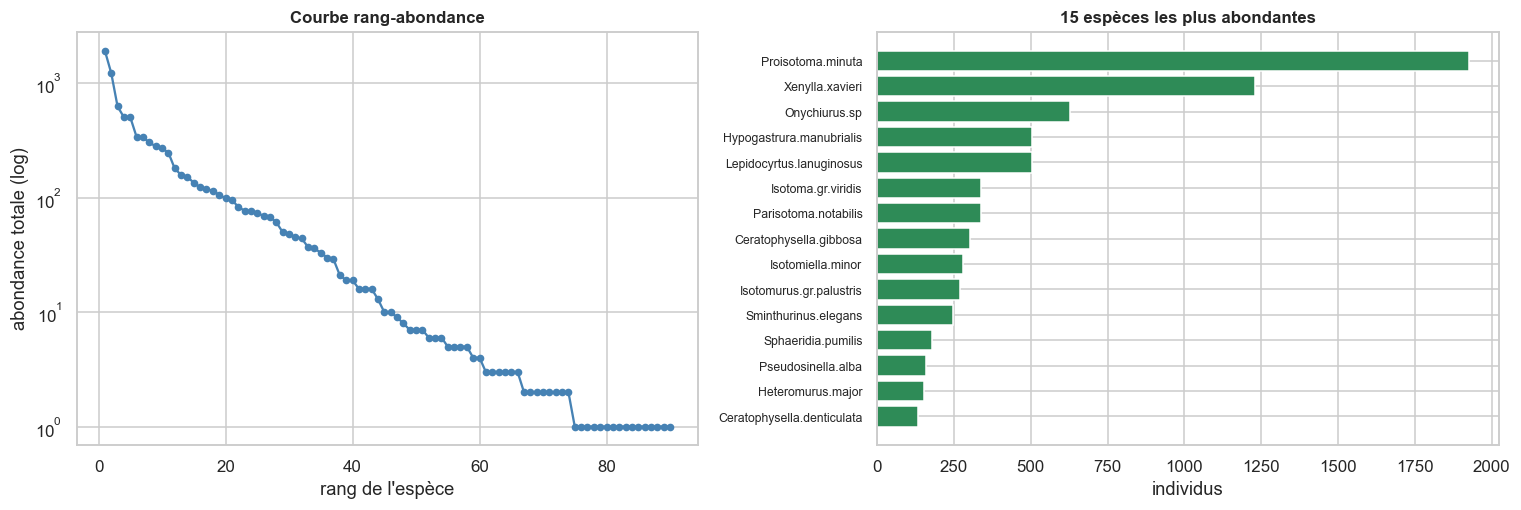

In [32]:
valeurs = abondance[abondance > 0].values

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(range(1, len(valeurs) + 1), valeurs, "o-", ms=4, color="steelblue")
axes[0].set_yscale("log")
axes[0].set_xlabel("rang de l'espèce")
axes[0].set_ylabel("abondance totale (log)")
axes[0].set_title("Courbe rang-abondance")

top15 = abondance.head(15)[::-1]
axes[1].barh(top15.index, top15.values, color="seagreen")
axes[1].set_title("15 espèces les plus abondantes")
axes[1].set_xlabel("individus")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

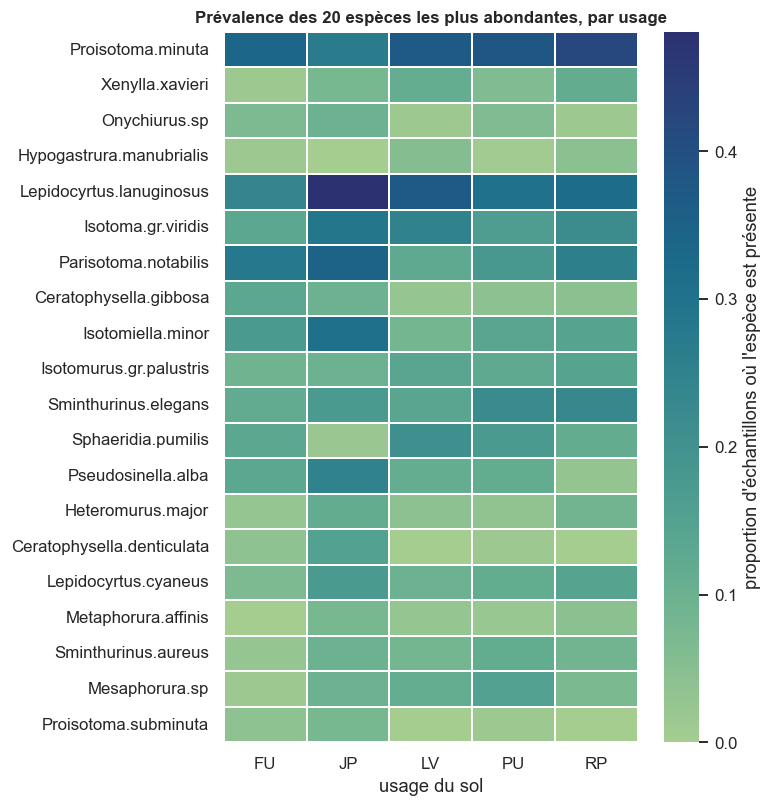

In [33]:
presence = ((especes > 0).astype(int)
            .assign(Echantillon=brut.Echantillon)
            .merge(dfa[["Echantillon", "land_use"]], on="Echantillon"))

top20 = abondance.head(20).index
matrice_presence = presence.groupby("land_use", observed=True)[list(top20)].mean().T

plt.figure(figsize=(7, 7.5))
sns.heatmap(matrice_presence, cmap="crest", linewidths=.3,
            cbar_kws={"label": "proportion d'échantillons où l'espèce est présente"})
plt.title("Prévalence des 20 espèces les plus abondantes, par usage")
plt.xlabel("usage du sol")
plt.ylabel("")
plt.show()

**Lecture.** La communauté est très inégale : quelques espèces portent l'essentiel des individus, la majorité est rare. Une espèce à faible prévalence ne peut pas être un bon indicateur stable d'un usage ; elle contribue surtout à la richesse `S`. Attention : le fichier ne contient que l'année 1 (`year1_train`), le jeu de test de l'année 2 n'est pas dans le dossier.

## 9. Synthèse

Tableau de bord des chiffres à retenir (tous recalculés ici) :

In [34]:
tableau = pd.Series({
    "échantillons (fichier brut)": len(df),
    "sites (fichier brut)": df.Site.nunique(),
    "échantillons analysés": len(dfa),
    "sites analysés": dfa.Site.nunique(),
    "réplicats par site (médiane)": int(df_site.n_rep.median()),
    "valeurs de J indéfinies": f"{100 * dfa.J.isna().mean():.0f} %",
    "part de variance de H portée par le site": f"{100 * eta2(dfa.H, dfa.Site):.0f} %",
    "cor(H, S), échantillons": round(dfa[["H", "S"]].corr().iloc[0, 1], 2),
    "cor(H, S), sites": round(df_site[["H", "S"]].corr().iloc[0, 1], 2),
    "|rho| maximal avec H": round(cor_site.loc["H"].abs().max(), 2),
    "conditionnement (sol + constante, sites)": f"{np.linalg.cond(add_constant(df_site[SOL]).values):.1e}",
    "VIF maximal (sol, sites)": f"{vif.max():.0f}",
    "asymétrie maximale (sol)": f"{asymetrie.max():.1f}",
    "explicatives après retrait séquentiel": len(explicatives),
})
tableau.to_frame("valeur")

,valeur
échantillons (fichier brut),418
sites (fichier brut),140
échantillons analysés,412
sites analysés,138
réplicats par site (médiane),3
valeurs de J indéfinies,20 %
part de variance de H portée par le site,47 %
"cor(H, S), échantillons",0.84
"cor(H, S), sites",0.87
|rho| maximal avec H,0.29


### Ce que l'exploration dit (et ne dit pas)

**Vérifié dans ce notebook :**

1. Le fichier est propre : pas de doublon, pas de code manquant inattendu. Les seuls manquants sont les `J` indéfinis pour `S ≤ 1` (81 sur 418, 20 %).
2. Les indices fournis sont exactement ceux que produit la matrice d'espèces (écart < 10⁻⁹).
3. Le sol est constant dans chaque site : 418 échantillons ne valent pas 418 observations indépendantes. Le site porte une part importante de la variance des indices.
4. Les relations sol ↔ diversité sont **faibles à modérées** (|rho| ≤ 0,35) et non linéaires : aucun prédicteur unique ne « explique » la diversité.
5. La colinéarité du sol est massive (VIF jusqu'à ~246 000) et vient de relations quasi exactes, pas d'un hasard d'échantillonnage.
6. Le plan est déséquilibré : Paris = 10 sites, seulement FU et JP.

**Ce que ce notebook ne fait pas :** aucun modèle, aucun test d'hypothèse complet, aucune sélection de variables définitive. Le choix final des explicatives revient au bloc modélisation, avec l'avis du prof sur les variables de sol à conserver.

### Prochaines étapes suggérées

- Verrouiller le jeu de travail : 138 sites, explicatives après retrait séquentiel, facteurs en indicatrices.
- Choisir la réponse (`H` est la plus naturelle ; `log(1+A)` pour l'abondance ; `J` impose de traiter les manquants).
- Prévoir un découpage **par site** (GroupKFold) et, si possible, un effet aléatoire site (modèle mixte) pour respecter la structure des données.
- Tester une transformation log sur les variables de sol asymétriques et vérifier les résidus partiels.
- Documenter l'ambiguïté de vocabulaire du sujet précédent le cas échéant : ici, « diversité » recouvre quatre indices différents (A, S, H, J), qui ne mesurent pas la même chose.

---

In [35]:
# Export optionnel du jeu de travail (décommenter si besoin pour le bloc modélisation)
# dfa.to_csv(DATA / "data_clean.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
# print("data_clean.csv écrit :", len(dfa), "lignes,", dfa.shape[1], "colonnes")

*Notebook d'exploration — les fichiers d'origine n'ont pas été modifiés. Les figures sont générées à l'exécution, rien n'est figé en dur.*